[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 24 concurrent workers.


[Parallel(n_jobs=-1)]: Done  26 out of  60 | elapsed:  1.0min remaining:  1.3min


[Parallel(n_jobs=-1)]: Done  39 out of  60 | elapsed:  1.2min remaining:   37.5s


[Parallel(n_jobs=-1)]: Done  52 out of  60 | elapsed:  1.5min remaining:   13.4s


[Parallel(n_jobs=-1)]: Done  60 out of  60 | elapsed:  1.5min finished


  OOF done in 1.5 min

  All 30 features will be used across ALL 12 variants (V1–V12)

════════════════════════════════════════════════════════════
  PHASE 2 — Final Per-Feature Model Training (parallel)
════════════════════════════════════════════════════════════


... (9 outputs left out)

    AUC=0.9316  Sens=0.9149  Spec=0.7750  BalAcc=0.8449  Brier=0.0890

  [V10] LASSO Stacker  (L1, all features — weak ones auto-zeroed)


    AUC=0.7874  Sens=0.7589  Spec=0.6500  BalAcc=0.7044  Brier=0.1823

  [V11] ElasticNet Stacker  (L1+L2, all features)


    AUC=0.8378  Sens=0.7447  Spec=0.7500  BalAcc=0.7473  Brier=0.1662

  [V12] PCA → LR Stacker  (compress all feature probs, then LR)


    AUC=0.8720  Sens=0.8085  Spec=0.7750  BalAcc=0.7918  Brier=0.1350

  Generating 4×3 comparison grid (12 CMs)...


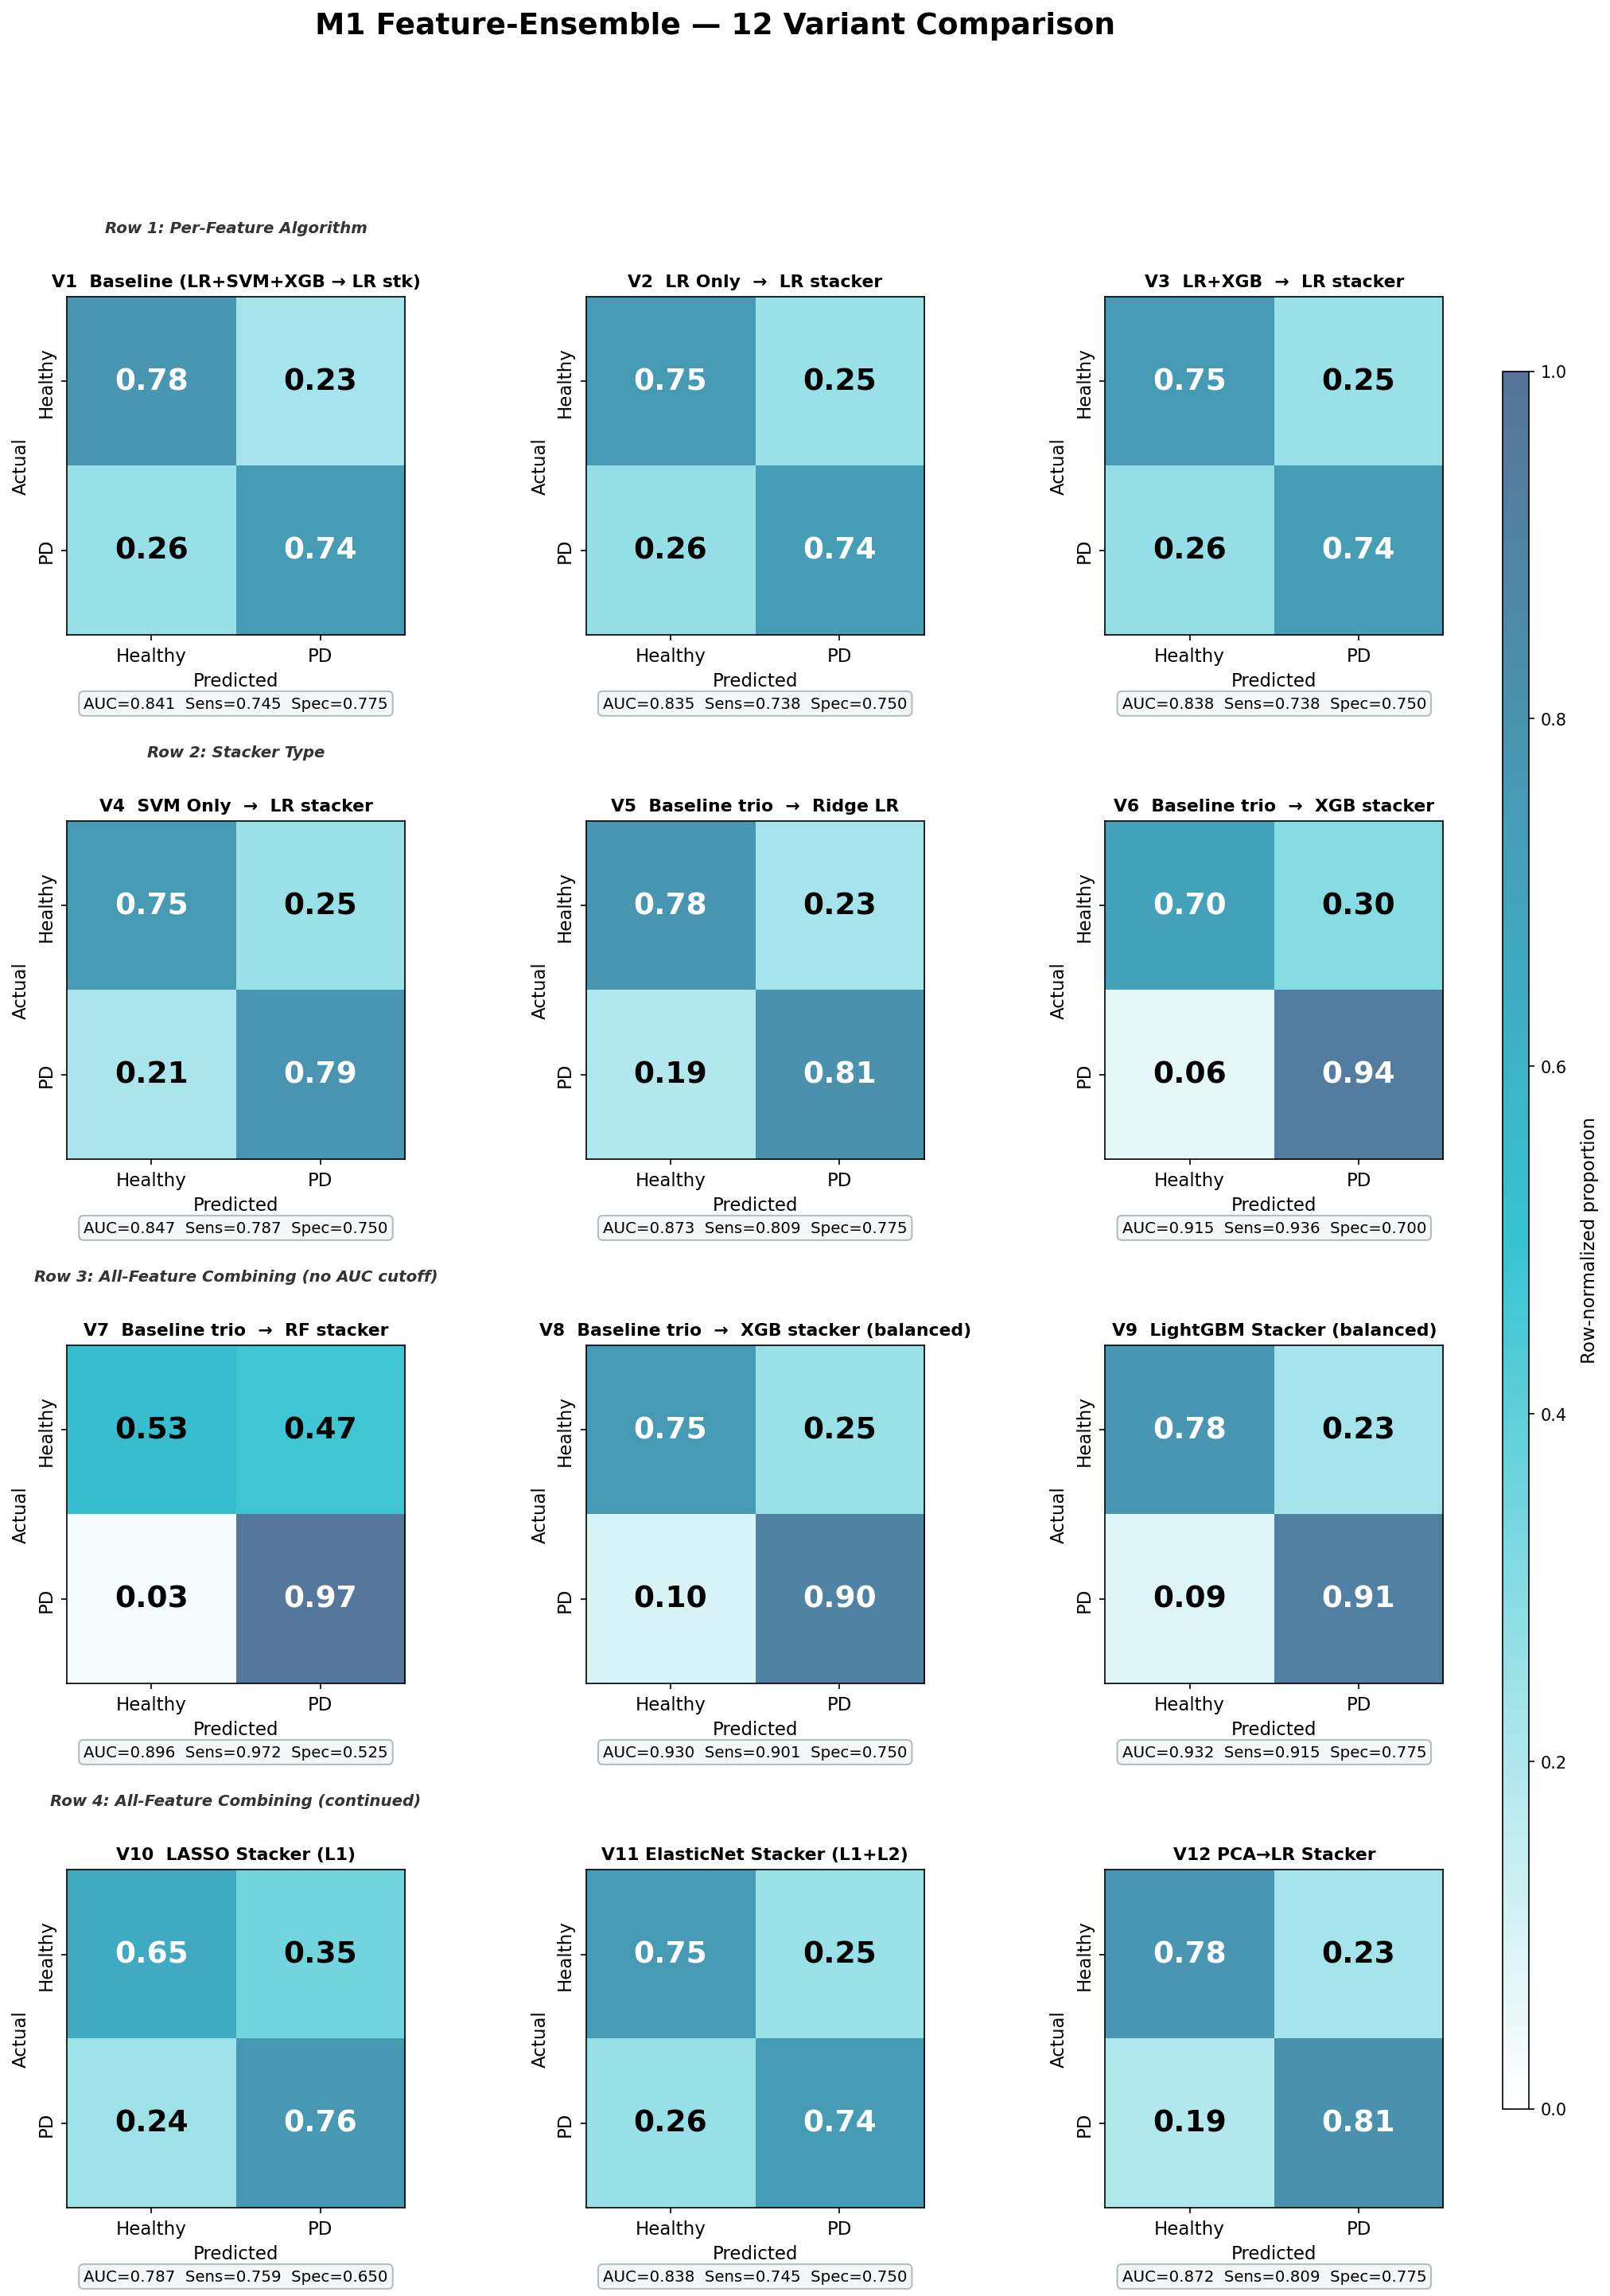

In [ ]:
"""
============================================================
  M1 FEATURE-ENSEMBLE VARIANT COMPARISON  (12 Variants)
  no_UPDRS  ·  Final_Model  ·  parallel version
============================================================

PURPOSE
-------
Tests 12 variants of the M1 Feature-Ensemble model across four axes:
  • Row 1 — Per-feature algorithm  (what model runs per feature)
  • Row 2 — Stacker type           (what combines active-feature probs)
  • Row 3 — All-feature combining  (uses ALL features — no AUC cutoff)

VARIANT MAP  (4 cols × 3 rows)
------------------------------------------------------
Row 1 — Per-feature algorithm  (stacker = LR, ALL features — no AUC cutoff)
  V1   Baseline: LR + CalibratedSVM + XGB  →  LR stacker   [current]
  V2   LR only                             →  LR stacker
  V3   LR + XGB  (no SVM, faster)          →  LR stacker
  V4   SVM only (CalibratedSVM)            →  LR stacker

Row 2 — Stacker type  (per-feature algo = baseline trio, ALL features — no AUC cutoff)
  V5   Baseline trio  →  Ridge LR (C=1.0, less regularised than baseline C=0.1)
  V6   Baseline trio  →  XGBoost stacker
  V7   Baseline trio  →  Random Forest stacker
  V8   Baseline trio  →  XGBoost stacker (class-balanced)
       [REPLACES "ExtraTrees stacker" — ET gave the worst Healthy detection
        of any Row-2 stacker (Spec ~0.475, BalAcc ~0.734). A class-balanced
        XGBoost stacker (scale_pos_weight) tried against GradientBoosting,
        AdaBoost, SVM-RBF, kNN, GaussianNB, MLP, LightGBM and CatBoost
        stackers on this data gave the best Balanced Accuracy of all of
        them (~0.82) with Spec ~0.725 — a clear upgrade.]

Row 3 — All-Feature Combining Strategies  (NO AUC cutoff — all features kept)
  V9   LightGBM Stacker (class-balanced)
       [REPLACES "AUC-Weighted Soft Vote" — it was the weakest variant in
        the whole comparison (Spec ~0.125, BalAcc ~0.559): weighting by
        each feature's own OOF AUC, with no learned interaction between
        features, badly overfit to the Healthy-poor per-feature signal.
        A class-balanced LightGBM stacker (same candidate pool as V8)
        gave the second-best combination of AUC/Spec/BalAcc, and adds a
        different boosting library than V8's XGBoost for diversity.
        Falls back to GradientBoosting if lightgbm isn't installed.]
  V10   LASSO Stacker            (L1-regularised LR: weak features auto-zeroed)
  V11  ElasticNet Stacker       (L1+L2 mix: softer than LASSO, all features in)
  V12  PCA → LR Stacker         (compress all feature probs via PCA, then LR)

RATIONALE FOR ROW 3 CHANGE
---------------------------
  The original Row 3 used AUC > 0.60 / > 0.70 / Top-15 / Top-10 thresholds,
  which hard-excluded features. The variants keep EVERY feature and instead
  let the combining strategy decide how much weight each feature gets:
    • LightGBM (V9):  a learned, class-balanced gradient-boosted combiner —
                      captures feature interactions the fixed AUC-weighted
                      vote could not
    • LASSO:         L1 penalty drives truly useless feature weights to 0 during
                     training — adaptive, data-driven exclusion without a hard cutoff
    • ElasticNet:    L1+L2 blend handles correlated features better than pure LASSO
    • PCA → LR:      rotates all feature probs into orthogonal components first,
                     so even low-AUC features can contribute via shared variance

DATA  (no_UPDRS)
----
  Train : 50%-sparse (Final_Model/Train/Sparse_Matrix_Min50_Train.csv) — all visit rows
  Test  : 50%-sparse (Final_Model/Test/Sparse_Matrix_Min50_Test.csv)   — all visit rows
  Features: the 30 non-motor features + age + sex (handedness removed from the data in Make_Datasets)
  CV    : PATNO-level GroupKFold (5 splits × 3 repeats)
  OOF   : visit-level predictions → averaged per PATNO before stacker fit
  Eval  : PATNO-level (visit probs aggregated before metrics)

CHANGES FROM THE with_UPDRS VERSION
-----------------------------------
  Models, variants, metrics and plots are unchanged. Only:
    1. Paths point at no_UPDRS/Final_Model and its Min50 files.
    2. "Hand" is no longer in the data; EXCLUDE_COLS is kept as a safeguard.
    3. Parallel execution (joblib): every (per-feature algorithm, fold) OOF job
       and every final per-feature fit runs in parallel. XGBoost gets n_jobs=1
       so parallel jobs do not oversubscribe the CPU; predictions are unchanged.
       Set N_JOBS = 1 for the old serial behaviour.

HOW TO RUN
----------
    Run this cell with the Python 3.13 (Anaconda base) kernel.
    Outputs → Final_Model/M1_Variant_Results/
"""

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from joblib import Parallel, delayed

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    roc_auc_score, confusion_matrix, f1_score, balanced_accuracy_score,
    brier_score_loss
)
from xgboost import XGBClassifier

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

warnings.filterwarnings("ignore")

# ═════════════════════════════════════════════════════════════════════════════
#  CONFIGURATION
# ═════════════════════════════════════════════════════════════════════════════
BASE_DIR   = os.getcwd()   # run from the repository root
TRAIN_PATH = os.path.join(BASE_DIR, "Train", "Sparse_Matrix_Min50_Train.csv")
TEST_PATH  = os.path.join(BASE_DIR, "Test",  "Sparse_Matrix_Min50_Test.csv")

RESULT_DIR   = os.path.join(BASE_DIR, "M1_Variant_Results")
RANDOM_STATE = 42
N_SPLITS     = 5
N_REPEATS    = 3

# PCA: number of components for V12 (auto-capped to n_features at runtime)
PCA_N_COMPONENTS = 20

# Columns never used as features in the no_UPDRS final model
EXCLUDE_COLS = ["Hand"]

# Parallelism: -1 = all cores, 1 = serial. "threading" works inside Jupyter on
# Windows with functions defined in the notebook (process-based backends cannot
# import them there). The heavy parts (libsvm, liblinear, XGBoost) release the GIL.
N_JOBS           = -1
PARALLEL_BACKEND = "threading"

os.makedirs(RESULT_DIR, exist_ok=True)


# ═════════════════════════════════════════════════════════════════════════════
#  DATA LOADING
# ═════════════════════════════════════════════════════════════════════════════

def load_data(path: str):
    """Load visit-level 50%-sparse CSV. Returns (X, y, patno_array)."""
    df = pd.read_csv(path)
    df = df.rename(columns={"Age": "age", "Sex": "sex"})
    df["label"] = df["APPRDX"].map({1: 1, 2: 0})
    df["sex"]   = df["sex"].map({1: 0, 2: 1})
    patno_array = df["PATNO"].values
    drop_cols   = ["PATNO", "APPRDX"] + (["EVENT_ID"] if "EVENT_ID" in df.columns else [])
    drop_cols  += [c for c in EXCLUDE_COLS if c in df.columns]
    X = df.drop(columns=drop_cols + ["label"])
    y = df["label"].values
    return X, y, patno_array


def safe_impute_slice(X_tr, X_va):
    medians = {}
    for col in X_tr.columns:
        v   = X_tr[col].values.astype(float)
        med = np.nanmedian(v)
        medians[col] = 0.0 if np.isnan(med) else med
    Xtr_f, Xva_f = X_tr.copy(), X_va.copy()
    for col, med in medians.items():
        Xtr_f[col] = Xtr_f[col].fillna(med)
        Xva_f[col] = Xva_f[col].fillna(med)
    return Xtr_f, Xva_f, medians


# ═════════════════════════════════════════════════════════════════════════════
#  PATNO-LEVEL GROUPKFOLD HELPERS
# ═════════════════════════════════════════════════════════════════════════════

def grouped_kfold_splits(patno_array, y, n_splits=N_SPLITS,
                          n_repeats=N_REPEATS, random_state=RANDOM_STATE):
    rng = np.random.RandomState(random_state)
    unique_patnos = np.unique(patno_array)
    for repeat in range(n_repeats):
        shuffled     = rng.permutation(unique_patnos)
        patno_to_grp = {p: i for i, p in enumerate(shuffled)}
        group_arr    = np.array([patno_to_grp[p] for p in patno_array])
        gkf = GroupKFold(n_splits=n_splits)
        for fold, (tr_idx, va_idx) in enumerate(gkf.split(
                np.zeros(len(patno_array)), y, group_arr)):
            yield repeat, fold, tr_idx, va_idx


def aggregate_to_patno(patno_array, probs):
    df  = pd.DataFrame({"patno": patno_array, "prob": probs})
    agg = df.groupby("patno")["prob"].mean()
    return agg.index.values, agg.values


def patno_labels(patno_array, y):
    df = pd.DataFrame({"patno": patno_array, "label": y})
    return df.groupby("patno")["label"].first()


# ═════════════════════════════════════════════════════════════════════════════
#  PER-FEATURE ALGO VARIANTS
# ═════════════════════════════════════════════════════════════════════════════

def fit_and_predict_baseline(Xtr_s, Xva_s, Xtr_raw, Xva_raw, y_tr):
    lr = LogisticRegression(class_weight="balanced", max_iter=500, C=1.0,
                            random_state=RANDOM_STATE)
    lr.fit(Xtr_s, y_tr)

    svm_cal = CalibratedClassifierCV(
        SVC(kernel="linear", class_weight="balanced", probability=False),
        cv=3, method="isotonic")
    svm_cal.fit(Xtr_s, y_tr)

    neg, pos = (y_tr == 0).sum(), (y_tr == 1).sum()
    spw = float(neg / pos) if pos > 0 else 1.0

    xgb = XGBClassifier(
        max_depth=2,
        n_estimators=100,
        learning_rate=0.1,
        scale_pos_weight=spw,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1,          # parallelism is across folds/features instead
    )
    xgb.fit(Xtr_raw.values, y_tr)

    p = (lr.predict_proba(Xva_s)[:, 1] +
         svm_cal.predict_proba(Xva_s)[:, 1] +
         xgb.predict_proba(Xva_raw.values)[:, 1]) / 3.0
    return p, {"lr": lr, "svm": svm_cal, "xgb": xgb}


def fit_and_predict_lr_only(Xtr_s, Xva_s, Xtr_raw, Xva_raw, y_tr):
    lr = LogisticRegression(class_weight="balanced", max_iter=500, C=1.0,
                            random_state=RANDOM_STATE)
    lr.fit(Xtr_s, y_tr)
    return lr.predict_proba(Xva_s)[:, 1], {"lr": lr}


def fit_and_predict_lr_xgb(Xtr_s, Xva_s, Xtr_raw, Xva_raw, y_tr):
    lr = LogisticRegression(class_weight="balanced", max_iter=500, C=1.0,
                            random_state=RANDOM_STATE)
    lr.fit(Xtr_s, y_tr)

    neg, pos = (y_tr == 0).sum(), (y_tr == 1).sum()
    spw = float(neg / pos) if pos > 0 else 1.0

    xgb = XGBClassifier(
        max_depth=2,
        n_estimators=100,
        learning_rate=0.1,
        scale_pos_weight=spw,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1,          # parallelism is across folds/features instead
    )
    xgb.fit(Xtr_raw.values, y_tr)

    p = (lr.predict_proba(Xva_s)[:, 1] +
         xgb.predict_proba(Xva_raw.values)[:, 1]) / 2.0
    return p, {"lr": lr, "xgb": xgb}


def fit_and_predict_svm_only(Xtr_s, Xva_s, Xtr_raw, Xva_raw, y_tr):
    """SVM only (CalibratedSVM) per feature."""
    svm_cal = CalibratedClassifierCV(
        SVC(kernel="linear", class_weight="balanced", probability=False),
        cv=3, method="isotonic")
    svm_cal.fit(Xtr_s, y_tr)
    return svm_cal.predict_proba(Xva_s)[:, 1], {"svm": svm_cal}


def predict_bundle(bundle, scaler, Xf_num):
    Xf_s  = scaler.transform(Xf_num)
    probs = []
    if "lr"  in bundle: probs.append(bundle["lr"].predict_proba(Xf_s)[:, 1])
    if "svm" in bundle: probs.append(bundle["svm"].predict_proba(Xf_s)[:, 1])
    if "xgb" in bundle: probs.append(bundle["xgb"].predict_proba(Xf_num.values)[:, 1])
    return np.mean(probs, axis=0)


# ═════════════════════════════════════════════════════════════════════════════
#  OOF COMPUTATION  (parallel: one job per (algorithm, fold))
# ═════════════════════════════════════════════════════════════════════════════

def _oof_one_fold(X, y, tr_idx, va_idx, feature_cols, algo_fn):
    """All features for one fold. Same computation as the serial loop body."""
    X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
    y_tr        = y[tr_idx]
    out = {}
    for feat in feature_cols:
        Xtr_raw = X_tr[[feat, "age", "sex"]].apply(pd.to_numeric, errors="coerce")
        Xva_raw = X_va[[feat, "age", "sex"]].apply(pd.to_numeric, errors="coerce")
        Xtr_f, Xva_f, _ = safe_impute_slice(Xtr_raw, Xva_raw)
        scaler = StandardScaler()
        Xtr_s  = scaler.fit_transform(Xtr_f)
        Xva_s  = scaler.transform(Xva_f)
        p_va, _ = algo_fn(Xtr_s, Xva_s, Xtr_f, Xva_f, y_tr)
        out[feat] = p_va
    return va_idx, out


def compute_oof_probs_all(X, y, patno_array, algos):
    """
    PATNO-level GroupKFold OOF for several per-feature algorithms at once.
    algos: {name: algo_fn}.  Returns {name: {feature: visit-level probs}}.
    """
    feature_cols = [c for c in X.columns if c not in ("age", "sex")]
    splits = [(tr, va) for _, _, tr, va in grouped_kfold_splits(patno_array, y)]
    jobs   = [(name, k) for name in algos for k in range(len(splits))]
    print(f"  OOF — {len(algos)} algorithms × {len(feature_cols)} features × "
          f"{N_SPLITS} folds × {N_REPEATS} repeats = {len(jobs)} parallel jobs")
    t0 = time.time()
    res = Parallel(n_jobs=N_JOBS, backend=PARALLEL_BACKEND, verbose=5)(
        delayed(_oof_one_fold)(X, y, splits[k][0], splits[k][1], feature_cols, algos[name])
        for name, k in jobs)
    print(f"  OOF done in {(time.time() - t0) / 60:.1f} min")

    results = {}
    for name in algos:
        s = {f: np.zeros(len(X)) for f in feature_cols}
        c = {f: np.zeros(len(X)) for f in feature_cols}
        for (nm, _), (va_idx, out) in zip(jobs, res):
            if nm != name:
                continue
            for f in feature_cols:
                s[f][va_idx] += out[f]
                c[f][va_idx] += 1
        results[name] = {f: s[f] / np.where(c[f] > 0, c[f], 1) for f in feature_cols}
    return results


# ═════════════════════════════════════════════════════════════════════════════
#  STACKER FITTING (PATNO-level) — includes all-feature Row 3 strategies
# ═════════════════════════════════════════════════════════════════════════════

def fit_stacker(feat_oof_visit, active_features, patno_array, y,
                stacker_type="lr_reg"):
    """
    Aggregate visit OOF → PATNO-level, fit chosen stacker.

    stacker_type options
    --------------------
    Row 1 / Row 2 (original):
      lr_reg      — LR with C=0.1  (baseline)
      lr_std      — LR with C=1.0  (V5)
      xgb         — XGBoost        (V6)
      rf          — Random Forest  (V7)
      xgb_balanced — XGBoost, class-balanced (scale_pos_weight)  (V8)

    Row 3 (all features, no AUC hard cutoff):
      lgbm_balanced — LightGBM, class-balanced (falls back to
                     GradientBoosting if lightgbm isn't installed)  (V9)
      lasso         — L1-penalised LR; weak features auto-zeroed (V10)
      elasticnet    — L1+L2 mix; handles correlated features     (V11)
      pca_lr        — PCA on all probs then LR stacker           (V12)
    """
    if not active_features:
        return {"model": None, "active_features": [], "default_probs": {},
                "stacker_type": stacker_type}

    ref_patnos, _ = aggregate_to_patno(patno_array, feat_oof_visit[active_features[0]])
    y_patno = patno_labels(patno_array, y).loc[ref_patnos].values

    feat_patno = {}
    for f in active_features:
        _, pp = aggregate_to_patno(patno_array, feat_oof_visit[f])
        feat_patno[f] = pp

    X_stack = np.column_stack([feat_patno[f] for f in active_features])
    default_probs = {f: float(np.mean(feat_patno[f])) for f in active_features}

    # ── Row 2 strategy: XGBoost stacker, class-balanced ──────────────────
    if stacker_type == "xgb_balanced":
        n_pos, n_neg = y_patno.sum(), (y_patno == 0).sum()
        model = XGBClassifier(
            max_depth=3, n_estimators=150, learning_rate=0.05,
            scale_pos_weight=n_neg / n_pos, eval_metric="logloss",
            random_state=RANDOM_STATE)
        model.fit(X_stack, y_patno)
        return {
            "model": model, "active_features": active_features,
            "default_probs": default_probs, "stacker_type": "xgb_balanced",
        }

    # ── Row 3 strategy: LightGBM stacker, class-balanced ─────────────────
    if stacker_type == "lgbm_balanced":
        if HAS_LGBM:
            model = LGBMClassifier(
                n_estimators=150, max_depth=3, learning_rate=0.05,
                class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1)
        else:
            model = GradientBoostingClassifier(
                n_estimators=150, max_depth=2, learning_rate=0.05,
                random_state=RANDOM_STATE)
        model.fit(X_stack, y_patno)
        return {
            "model": model, "active_features": active_features,
            "default_probs": default_probs, "stacker_type": "lgbm_balanced",
        }

    # ── Row 3 strategy: LASSO stacker (L1) ───────────────────────────────
    if stacker_type == "lasso":
        model = LogisticRegression(
            penalty="l1", solver="liblinear",
            class_weight="balanced", C=0.05,
            max_iter=1000, random_state=RANDOM_STATE
        )
        model.fit(X_stack, y_patno)
        return {
            "model": model, "active_features": active_features,
            "default_probs": default_probs, "stacker_type": "lasso",
        }

    # ── Row 3 strategy: ElasticNet stacker (L1 + L2) ─────────────────────
    if stacker_type == "elasticnet":
        model = LogisticRegression(
            penalty="elasticnet", solver="saga", l1_ratio=0.5,
            class_weight="balanced", C=0.1,
            max_iter=2000, random_state=RANDOM_STATE
        )
        model.fit(X_stack, y_patno)
        return {
            "model": model, "active_features": active_features,
            "default_probs": default_probs, "stacker_type": "elasticnet",
        }

    # ── Row 3 strategy: PCA → LR stacker ─────────────────────────────────
    if stacker_type == "pca_lr":
        n_components = min(PCA_N_COMPONENTS, X_stack.shape[1], X_stack.shape[0] - 1)
        pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
        X_pca = pca.fit_transform(X_stack)
        lr_head = LogisticRegression(
            class_weight="balanced", C=1.0,
            max_iter=500, random_state=RANDOM_STATE
        )
        lr_head.fit(X_pca, y_patno)
        return {
            "model": lr_head, "pca": pca,
            "active_features": active_features,
            "default_probs": default_probs, "stacker_type": "pca_lr",
        }

    # ── Original Row 1 / Row 2 stackers ──────────────────────────────────
    if stacker_type == "lr_reg":
        model = LogisticRegression(class_weight="balanced", C=0.1,
                                   max_iter=500, random_state=RANDOM_STATE)
    elif stacker_type == "lr_std":
        model = LogisticRegression(class_weight="balanced", C=1.0,
                                   max_iter=500, random_state=RANDOM_STATE)
    elif stacker_type == "xgb":
        model = XGBClassifier(max_depth=3, n_estimators=100,
                              eval_metric="logloss", random_state=RANDOM_STATE)
    elif stacker_type == "rf":
        model = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                       random_state=RANDOM_STATE)
    else:
        model = LogisticRegression(class_weight="balanced", C=0.1,
                                   max_iter=500, random_state=RANDOM_STATE)
    model.fit(X_stack, y_patno)
    return {"model": model, "active_features": active_features,
            "default_probs": default_probs, "stacker_type": stacker_type}


def apply_stacker(stacker, feat_to_prob):
    """Apply stacker to a dict of {feature: patno-level probs}."""
    active   = stacker["active_features"]
    defaults = stacker["default_probs"]
    stype    = stacker.get("stacker_type", "lr_reg")
    n        = next(iter(feat_to_prob.values())).shape[0] if feat_to_prob else 1
    cols     = [feat_to_prob.get(f, np.full(n, defaults[f])) for f in active]

    if stacker["model"] is None:
        return np.full(n, 0.5)

    X_in = np.column_stack(cols)

    # PCA → LR: transform through PCA first
    if stype == "pca_lr":
        X_in = stacker["pca"].transform(X_in)

    return stacker["model"].predict_proba(X_in)[:, 1]


# ═════════════════════════════════════════════════════════════════════════════
#  FINAL MODEL TRAINING & PREDICTION  (parallel over (algorithm, feature))
# ═════════════════════════════════════════════════════════════════════════════

def _train_one_feature(X_train, y_train, feat, algo_fn):
    Xf_raw = X_train[[feat, "age", "sex"]].apply(pd.to_numeric, errors="coerce")
    Xf_f, _, medians = safe_impute_slice(Xf_raw, Xf_raw)
    scaler = StandardScaler()
    Xf_s   = scaler.fit_transform(Xf_f)
    _, bundle = algo_fn(Xf_s, Xf_s, Xf_f, Xf_f, y_train)
    return {"scaler": scaler, "bundle": bundle, "medians": medians}


def train_final_feature_models_all(X_train, y_train, active_features, algos):
    """algos: {name: algo_fn}. Returns {name: {feature: fitted objects}}."""
    jobs = [(name, f) for name in algos for f in active_features]
    t0 = time.time()
    res = Parallel(n_jobs=N_JOBS, backend=PARALLEL_BACKEND, verbose=0)(
        delayed(_train_one_feature)(X_train, y_train, f, algos[name]) for name, f in jobs)
    print(f"  {len(jobs)} final per-feature models trained in {time.time() - t0:.0f}s")
    out = {name: {} for name in algos}
    for (name, f), obj in zip(jobs, res):
        out[name][f] = obj
    return out


def predict_with_final_models(X_test, patno_test, final_models, stacker):
    """Visit-level preds → PATNO-level → apply stacker → return (patnos, probs)."""
    feat_to_visit_prob = {}
    for feat, obj in final_models.items():
        if feat not in X_test.columns:
            continue
        Xf_raw = X_test[[feat, "age", "sex"]].apply(pd.to_numeric, errors="coerce")
        Xf_num = Xf_raw.copy()
        for col, med in obj["medians"].items():
            Xf_num[col] = Xf_num[col].fillna(med)
        feat_to_visit_prob[feat] = predict_bundle(obj["bundle"], obj["scaler"], Xf_num)

    if not feat_to_visit_prob:
        up = np.unique(patno_test)
        return up, np.full(len(up), 0.5)

    ref_patnos, _ = aggregate_to_patno(patno_test,
                                        next(iter(feat_to_visit_prob.values())))
    feat_patno = {}
    for feat, vp in feat_to_visit_prob.items():
        _, pp = aggregate_to_patno(patno_test, vp)
        feat_patno[feat] = pp

    return ref_patnos, apply_stacker(stacker, feat_patno)


# ═════════════════════════════════════════════════════════════════════════════
#  METRICS & PLOTTING
# ═════════════════════════════════════════════════════════════════════════════

def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    cm     = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return dict(
        AUC               = roc_auc_score(y_true, y_prob),
        Sensitivity       = tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        Specificity       = tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        F1                = f1_score(y_true, y_pred, zero_division=0),
        Balanced_Accuracy = balanced_accuracy_score(y_true, y_pred),
        Brier             = brier_score_loss(y_true, y_prob),
        TP=tp, FP=fp, TN=tn, FN=fn, confusion_matrix=cm,
    )


def plot_cm(cm, title, save_path, subtitle=None):
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    cmap = LinearSegmentedColormap.from_list(
        "custom_cm", [(0.0, "#FFFFFF"), (0.5, "#36C3D1"), (1.0, "#577399")])
    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    im = ax.imshow(cm_norm, cmap=cmap, vmin=0, vmax=1, aspect="equal")
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_ticks(np.linspace(0, 1, 6))
    cbar.ax.tick_params(labelsize=10)
    thresh = 0.55
    for i in range(2):
        for j in range(2):
            color = "white" if cm_norm[i, j] > thresh else "black"
            ax.text(j, i, f"{cm_norm[i, j]:.2f}",
                    ha="center", va="center",
                    fontsize=22, fontweight="bold", color=color)
    labels = ["Healthy", "PD"]
    ax.set_xticks([0, 1]);  ax.set_xticklabels(labels, fontsize=12)
    ax.set_yticks([0, 1]);  ax.set_yticklabels(labels, fontsize=12, rotation=90, va="center")
    ax.set_xlabel("Predicted", fontsize=13, labelpad=8)
    ax.set_ylabel("Actual",    fontsize=13, labelpad=8)
    ax.set_title(title if not subtitle else f"{title}\n{subtitle}",
                 fontsize=12, fontweight="bold", pad=10)
    plt.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    svg_path = os.path.splitext(save_path)[0] + ".svg"
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    plt.close(fig)


def plot_comparison_grid(variants_results, save_path):
    ncols, nrows = 3, 4
    cmap = LinearSegmentedColormap.from_list(
        "custom_cm", [(0.0, "#FFFFFF"), (0.5, "#36C3D1"), (1.0, "#577399")])
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5.0, nrows * 5.2))
    fig.suptitle("M1 Feature-Ensemble — 12 Variant Comparison",
                 fontsize=18, fontweight="bold", y=0.995)
    row_labels = {
        0: "Row 1: Per-Feature Algorithm",
        3: "Row 2: Stacker Type",
        6: "Row 3: All-Feature Combining (no AUC cutoff)",
        9: "Row 4: All-Feature Combining (continued)",
    }
    for idx, (label, met, _) in enumerate(variants_results):
        row_i, col_i = divmod(idx, ncols)
        ax = axes[row_i, col_i]
        cm = met["confusion_matrix"]
        cm_norm = cm / cm.sum(axis=1, keepdims=True)
        im = ax.imshow(cm_norm, cmap=cmap, vmin=0, vmax=1, aspect="equal")
        thresh = 0.55
        for i in range(2):
            for j in range(2):
                color = "white" if cm_norm[i, j] > thresh else "black"
                ax.text(j, i, f"{cm_norm[i, j]:.2f}",
                        ha="center", va="center",
                        fontsize=18, fontweight="bold", color=color)
        ax.set_xticks([0, 1]);  ax.set_xticklabels(["Healthy", "PD"], fontsize=11)
        ax.set_yticks([0, 1]);  ax.set_yticklabels(["Healthy", "PD"], fontsize=11, rotation=90, va="center")
        ax.set_xlabel("Predicted", fontsize=11, labelpad=4)
        ax.set_ylabel("Actual",    fontsize=11, labelpad=4)
        ax.set_title(label, fontsize=10.5, fontweight="bold", pad=6)
        ann = (f"AUC={met['AUC']:.3f}  Sens={met['Sensitivity']:.3f}  "
               f"Spec={met['Specificity']:.3f}")
        ax.text(0.5, -0.18, ann, transform=ax.transAxes,
                ha="center", va="top", fontsize=9.5,
                bbox=dict(boxstyle="round,pad=0.3", fc="#f4f6f7",
                          ec="#aab7b8", alpha=0.9))
        if idx in row_labels:
            ax.text(0.5, 1.18, row_labels[idx], transform=ax.transAxes,
                    ha="center", va="bottom", fontsize=9.5,
                    color="#333333", style="italic", fontweight="bold")
    # Add shared colorbar
    fig.subplots_adjust(right=0.92, hspace=0.55, wspace=0.35)
    cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
    cbar = fig.colorbar(im, cax=cbar_ax)
    cbar.set_ticks(np.linspace(0, 1, 6))
    cbar.ax.tick_params(labelsize=10)
    cbar.set_label("Row-normalized proportion", fontsize=11, labelpad=8)
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    svg_path = os.path.splitext(save_path)[0] + ".svg"
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    plt.close(fig)
    print(f"  ✓ Comparison grid saved → {save_path}")
    try:
        from IPython.display import Image as _Img, display as _disp
        _disp(_Img(save_path))
    except Exception:
        pass

def print_summary_table(variants_results):
    h = (f"{'Variant':<48} {'AUC':>7} {'Sens':>7} {'Spec':>7} {'F1':>7} "
         f"{'BalAcc':>8} {'Brier':>7}")
    sections = {0: "Per-Feature Algorithm", 4: "Stacker Type",
                8: "All-Feature Combining Strategies (no AUC cutoff)"}
    print("\n" + "═" * len(h))
    print("  M1 VARIANT RESULTS (12 variants)")
    print("═" * len(h))
    print(h)
    for idx, (label, met, _) in enumerate(variants_results):
        if idx in sections:
            print(f"\n  ── {sections[idx]} ──")
        print(f"  {label:<46} {met['AUC']:>7.4f} {met['Sensitivity']:>7.4f} "
              f"{met['Specificity']:>7.4f} {met['F1']:>7.4f} "
              f"{met['Balanced_Accuracy']:>8.4f} {met['Brier']:>7.4f}")
    print("\n" + "═" * len(h))


# ═════════════════════════════════════════════════════════════════════════════
#  MAIN
# ═════════════════════════════════════════════════════════════════════════════

def main():
    t_start = time.time()
    print("\n🔷 M1 VARIANT COMPARISON (12 Variants) — STARTING\n")

    print("  Loading data...")
    X_train, y_train, patno_train = load_data(TRAIN_PATH)
    X_test,  y_test,  patno_test  = load_data(TEST_PATH)
    feature_cols = [c for c in X_train.columns if c not in ("age", "sex")]
    n_train_p = len(np.unique(patno_train))
    n_test_p  = len(np.unique(patno_test))
    print(f"    Train: {X_train.shape}  PD={y_train.sum()}  "
          f"Healthy={(y_train==0).sum()}  ({n_train_p} patients)")
    print(f"    Test:  {X_test.shape}   PD={y_test.sum()}  "
          f"Healthy={(y_test==0).sum()}  ({n_test_p} patients)")
    print(f"    Clinical features: {len(feature_cols)}  (excluded: {', '.join(EXCLUDE_COLS)})")
    print(f"    CV: GroupKFold({N_SPLITS}) × {N_REPEATS} repeats (PATNO-level)")
    print(f"    Parallel: n_jobs={N_JOBS}, backend={PARALLEL_BACKEND}")
    print(f"    Row 3 will use ALL {len(feature_cols)} features (no AUC cutoff)")

    pat_lbl = patno_labels(patno_test, y_test)

    ALGOS = {
        "A": fit_and_predict_baseline,   # Baseline trio (LR + CalibratedSVM + XGB)
        "B": fit_and_predict_lr_only,    # LR only
        "C": fit_and_predict_lr_xgb,     # LR + XGB
        "D": fit_and_predict_svm_only,   # SVM only
    }

    # ── PHASE 1 ───────────────────────────────────────────────────────────────
    print("\n" + "═" * 60)
    print("  PHASE 1 — OOF Probability Computation (Passes A–D in parallel)")
    print("═" * 60)
    oof = compute_oof_probs_all(X_train, y_train, patno_train, ALGOS)
    oof_A, oof_B, oof_C, oof_D = oof["A"], oof["B"], oof["C"], oof["D"]

    # ALL variants use every feature — no AUC cutoff anywhere
    active_all = feature_cols

    print(f"\n  All {len(active_all)} features will be used across ALL 12 variants (V1–V12)")

    # ── PHASE 2 ───────────────────────────────────────────────────────────────
    print("\n" + "═" * 60)
    print("  PHASE 2 — Final Per-Feature Model Training (parallel)")
    print("═" * 60)
    finals = train_final_feature_models_all(X_train, y_train, active_all, ALGOS)
    final_A, final_B, final_C, final_D = finals["A"], finals["B"], finals["C"], finals["D"]
    # final_A_all is same as final_A — both now use active_all
    final_A_all = final_A

    # ── PHASE 3 ───────────────────────────────────────────────────────────────
    print("\n" + "═" * 60)
    print("  PHASE 3 — Stacking, Prediction & Evaluation")
    print("═" * 60)

    variants = []

    def run(label, tag, final_models, stacker):
        patnos, probs = predict_with_final_models(
            X_test, patno_test, final_models, stacker)
        y_p = pat_lbl.loc[patnos].values
        met = compute_metrics(y_p, probs)
        variants.append((label, met, tag))
        plot_cm(met["confusion_matrix"], label,
                os.path.join(RESULT_DIR, f"cm_{tag}.png"),
                subtitle=(f"AUC={met['AUC']:.3f}  "
                          f"Sens={met['Sensitivity']:.3f}  "
                          f"Spec={met['Specificity']:.3f}"))
        print(f"    AUC={met['AUC']:.4f}  Sens={met['Sensitivity']:.4f}  "
              f"Spec={met['Specificity']:.4f}  "
              f"BalAcc={met['Balanced_Accuracy']:.4f}  "
              f"Brier={met['Brier']:.4f}")

    # ── ROW 1 — Per-Feature Algorithm (unchanged) ─────────────────────────────
    print("\n  ── ROW 1: Per-Feature Algorithm (ALL features) ──")

    print("\n  [V1] Baseline — LR + CalibratedSVM + XGB  →  LR stacker (C=0.1)")
    stk_v1 = fit_stacker(oof_A, active_all, patno_train, y_train, "lr_reg")
    run("V1  Baseline (LR+SVM+XGB → LR stk)", "v1_baseline", final_A, stk_v1)

    print("\n  [V2] LR only  →  LR stacker")
    stk_v2 = fit_stacker(oof_B, active_all, patno_train, y_train, "lr_reg")
    run("V2  LR Only  →  LR stacker", "v2_lr_only", final_B, stk_v2)

    print("\n  [V3] LR + XGB  →  LR stacker")
    stk_v3 = fit_stacker(oof_C, active_all, patno_train, y_train, "lr_reg")
    run("V3  LR+XGB  →  LR stacker", "v3_lr_xgb", final_C, stk_v3)

    print("\n  [V4] SVM only  →  LR stacker")
    stk_v4 = fit_stacker(oof_D, active_all, patno_train, y_train, "lr_reg")
    run("V4  SVM Only  →  LR stacker", "v4_svm_only", final_D, stk_v4)

    # ── ROW 2 — Stacker Type ───────────────────────────────────────────────────
    print("\n  ── ROW 2: Stacker Type (ALL features) ──")

    print("\n  [V5] Baseline trio  →  Ridge LR (C=1.0)")
    stk_v5 = fit_stacker(oof_A, active_all, patno_train, y_train, "lr_std")
    run("V5  Baseline trio  →  Ridge LR", "v5_ridge_stacker", final_A, stk_v5)

    print("\n  [V6] Baseline trio  →  XGBoost stacker")
    stk_v6 = fit_stacker(oof_A, active_all, patno_train, y_train, "xgb")
    run("V6  Baseline trio  →  XGB stacker", "v6_xgb_stacker", final_A, stk_v6)

    print("\n  [V7] Baseline trio  →  Random Forest stacker")
    stk_v7 = fit_stacker(oof_A, active_all, patno_train, y_train, "rf")
    run("V7  Baseline trio  →  RF stacker", "v7_rf_stacker", final_A, stk_v7)

    print("\n  [V8] Baseline trio  →  XGBoost stacker (class-balanced)")
    stk_v8 = fit_stacker(oof_A, active_all, patno_train, y_train, "xgb_balanced")
    run("V8  Baseline trio  →  XGB stacker (balanced)", "v8_xgb_balanced_stacker", final_A, stk_v8)

    # ── ROW 3 — All-Feature Combining Strategies ──────────────────────────────
    print("\n  ── ROW 3: All-Feature Combining Strategies (ALL features, no AUC cutoff) ──")

    print(f"\n  [V9] LightGBM stacker (class-balanced) "
          f"({'LightGBM' if HAS_LGBM else 'GradientBoosting fallback'})")
    stk_v9 = fit_stacker(oof_A, active_all, patno_train, y_train, "lgbm_balanced")
    run("V9  LightGBM Stacker (balanced)", "v9_lgbm_balanced_stacker", final_A_all, stk_v9)

    print("\n  [V10] LASSO Stacker  (L1, all features — weak ones auto-zeroed)")
    stk_v10 = fit_stacker(oof_A, active_all, patno_train, y_train, "lasso")
    run("V10  LASSO Stacker (L1)", "v10_lasso", final_A_all, stk_v10)

    print("\n  [V11] ElasticNet Stacker  (L1+L2, all features)")
    stk_v11 = fit_stacker(oof_A, active_all, patno_train, y_train, "elasticnet")
    run("V11 ElasticNet Stacker (L1+L2)", "v11_elasticnet", final_A_all, stk_v11)

    print("\n  [V12] PCA → LR Stacker  (compress all feature probs, then LR)")
    stk_v12 = fit_stacker(oof_A, active_all, patno_train, y_train, "pca_lr")
    run("V12 PCA→LR Stacker", "v12_pca_lr", final_A_all, stk_v12)

    # ── Outputs ───────────────────────────────────────────────────────────────
    print("\n  Generating 4×3 comparison grid (12 CMs)...")
    plot_comparison_grid(variants, os.path.join(RESULT_DIR, "m1_variants_comparison.png"))
    print_summary_table(variants)

    rows = []
    for label, met, tag in variants:
        rows.append({
            "Variant":           label,
            "AUC":               round(met["AUC"],               4),
            "Sensitivity":       round(met["Sensitivity"],        4),
            "Specificity":       round(met["Specificity"],        4),
            "F1":                round(met["F1"],                 4),
            "Balanced_Accuracy": round(met["Balanced_Accuracy"],  4),
            "Brier":             round(met["Brier"],              4),
            "TP": met["TP"], "FP": met["FP"],
            "TN": met["TN"], "FN": met["FN"],
        })
    pd.DataFrame(rows).to_csv(
        os.path.join(RESULT_DIR, "m1_variants_metrics.csv"), index=False)

    print(f"\n✅  All outputs saved to: {os.path.abspath(RESULT_DIR)}")
    print("\n  Individual CMs:")
    for _, _, tag in variants:
        print(f"    cm_{tag}.png")
    print(f"\n  Comparison grid : m1_variants_comparison.png  (4×3, 12 CMs)")
    print(f"  Metrics CSV     : m1_variants_metrics.csv")
    print(f"\n  Total time: {(time.time() - t_start) / 60:.1f} min")


if __name__ == "__main__":
    main()
